In [1]:
import sys
import os

In [2]:
project_root = os.path.abspath(os.path.join(os.getcwd(), "..", "..", ".."))

if project_root not in sys.path:
    sys.path.append(project_root)

In [3]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
        
from core.models import GetModel
import json

In [4]:
def GetModelFromConfig(path):
    config_path =  "config.json"
    with open(config_path, "r") as f:
        config = json.load(f)
                
    model = GetModel(config)
    
    return model, config["experiment"]["N"]

In [5]:
import plotly.graph_objects as go
from sklearn.decomposition import PCA
import numpy as np

def plot_input_only_plotly(model, N):
    weights = model.tokens_embed.weight.detach().cpu().numpy()

    offset = 2 * N * N 
    labels = np.arange(-N, N + 1)
    indices = labels + offset
    
    valid_indices = [i for i in indices if 0 <= i < weights.shape[0]]
    input_weights = weights[valid_indices]
    labels = labels[:len(valid_indices)]
    
    pca = PCA(n_components=2)
    embeds_2d = pca.fit_transform(input_weights)
    

    fig = go.Figure()
    
    fig.add_trace(go.Scatter(
        x=embeds_2d[:, 0],
        y=embeds_2d[:, 1],
        mode='markers+text',
        text=[str(l) for l in labels],
        textposition="top center",
        marker=dict(
            size=14,
            color='red',
            line=dict(width=1, color='black')
        ),
        hoverinfo='text',
        hovertext=[f"Wartość wejściowa: {l}<br>Index w embed: {l + offset}" for l in labels]
    ))
    
    fig.update_layout(
        title=f"Struktura liczb wejściowych (Embeddings) dla N={N}",
        xaxis_title="PCA Component 1",
        yaxis_title="PCA Component 2",
        plot_bgcolor='white',
        width=700,
        height=700
    )
    
    fig.update_xaxes(showgrid=True, gridcolor='lightgray')
    fig.update_yaxes(showgrid=True, gridcolor='lightgray')
    
    fig.show()

In [6]:
model, N = GetModelFromConfig("")

model_path = r"checkpoint_epoch_8000.pt"

checkpoint = torch.load(model_path, map_location="cpu")

model_weights = checkpoint["model_state_dict"]
model.load_state_dict(model_weights)

plot_input_only_plotly(model, N=N)

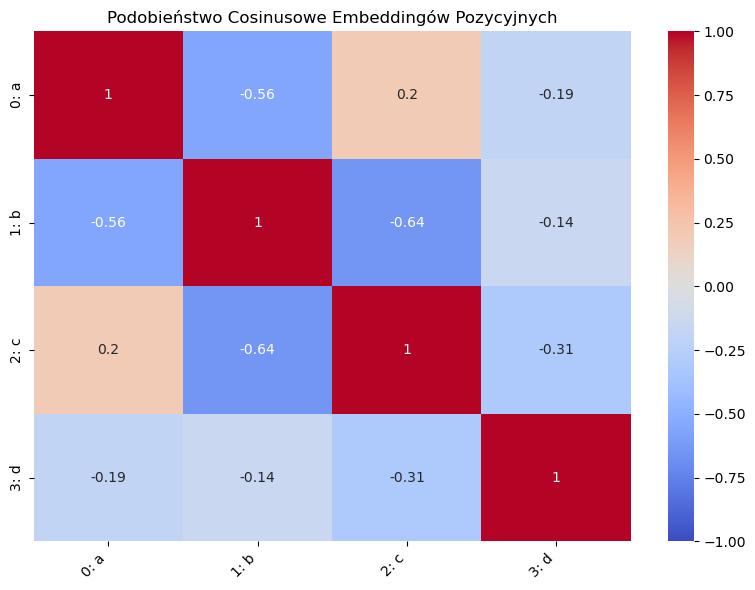

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def analyze_positional_embeddings(model):
    pos_weights = model.pos_embed.weight.detach().cpu().numpy()
    
    norm = np.linalg.norm(pos_weights, axis=1, keepdims=True)
    normalized_pos = pos_weights / norm
    
    cosine_sim = np.dot(normalized_pos, normalized_pos.T)
    
    plt.figure(figsize=(8, 6))
    

    labels = [
        '0: a', '1: b', '2: c', '3: d',
    ]
    
    sns.heatmap(
        cosine_sim, 
        annot=True, 
        cmap="coolwarm", 
        xticklabels=labels, 
        yticklabels=labels,
        vmin=-1, vmax=1
    )
    
    plt.title("Podobieństwo Cosinusowe Embeddingów Pozycyjnych")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


analyze_positional_embeddings(model)

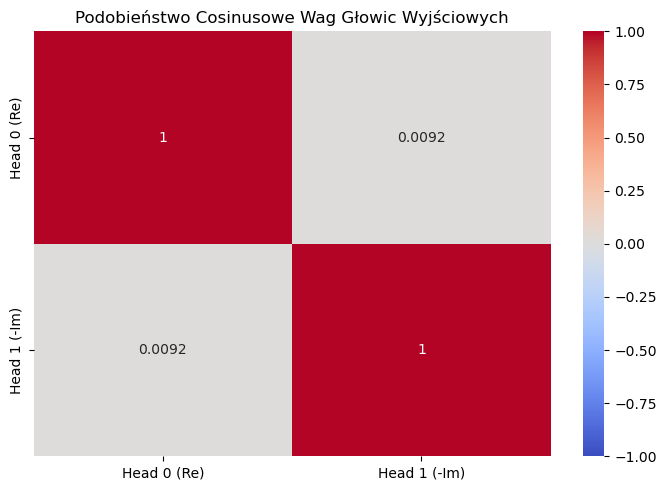

In [8]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def analyze_output_heads(model):
    heads_weights = [head.weight.detach().cpu().numpy() for head in model.output_heads]
    
    flat_heads = [w.flatten() for w in heads_weights]
    flat_heads = np.array(flat_heads) 

    norm = np.linalg.norm(flat_heads, axis=1, keepdims=True)
    normalized_heads = flat_heads / norm
    head_sim = np.dot(normalized_heads, normalized_heads.T)
    

    labels = ['Head 0 (Re)', 'Head 1 (-Im)']
    
    plt.figure(figsize=(7, 5))
    sns.heatmap(
        head_sim, 
        annot=True, 
        cmap="coolwarm", 
        xticklabels=labels, 
        yticklabels=labels,
        vmin=-1, vmax=1
    )
    plt.title("Podobieństwo Cosinusowe Wag Głowic Wyjściowych")
    plt.tight_layout()
    plt.show()

analyze_output_heads(model)

In [16]:
import numpy as np
import plotly.graph_objects as go
from sklearn.decomposition import PCA

def plot_output_head_plotly(model, N, head_idx=0):
    """
    Rysuje interaktywny wykres 2D PCA dla wybranej głowicy wyjściowej.
    head_idx: 0 -> Re (górna lewa), 1 -> -Im (górna prawa), 2 -> Im (dolna lewa), 3 -> Re (dolna prawa)
    """
    weights = model.output_heads[head_idx].weight.detach().cpu().numpy()
    

    output_offset = 2 * N * N
    min_val, max_val = -2 * N * N, 2 * N * N
    active_indices = []
    labels = []
    
    for val in range(min_val, max_val + 1):
        idx = val + output_offset
        if 0 <= idx < weights.shape[0]:
            active_indices.append(idx)
            labels.append(val)

    active_weights = weights[active_indices]


    weight_norms = np.linalg.norm(active_weights, axis=1)
    valid_mask = weight_norms > 0.3
    
    active_weights = active_weights[valid_mask]
    labels = np.array(labels)[valid_mask]

    pca = PCA(n_components=2)
    embeds_2d = pca.fit_transform(active_weights)
    

    head_names = {0: "Re (Head 0)", 1: "Im (Head 1)"}
    title_name = head_names.get(head_idx, f"Head {head_idx}")

    fig = go.Figure()

    fig.add_trace(go.Scatter(
        x=embeds_2d[:, 0],
        y=embeds_2d[:, 1],
        mode='markers+text',
        text=[str(l) for l in labels],
        textposition="top right",
        textfont=dict(size=10, family="Arial Black"),
        marker=dict(
            size=12,
            color=labels,
            colorscale='RdBu',
            showscale=True,
            colorbar=dict(title=f"Wartość {title_name.split()[0]}"),
            line=dict(width=1, color='Black')
        ),
        hoverinfo='text',
        hovertext=[f"Token ID: {l + output_offset}<br>Wartość algebraiczna: {l}" for l in labels]
    ))

    fig.update_layout(
        title=dict(
            text=f"Interaktywna struktura wyjść dla {title_name} (N={N})",
            x=0.5,
            xanchor='center'
        ),
        xaxis=dict(title="PCA Component 1", gridcolor='rgba(200,200,200,0.2)'),
        yaxis=dict(title="PCA Component 2", gridcolor='rgba(200,200,200,0.2)'),
        plot_bgcolor='white',
        paper_bgcolor='white',
        width=900,
        height=800,
        showlegend=False
    )
    
    fig.show()

In [17]:
plot_output_head_plotly(model, N=N, head_idx=0)

plot_output_head_plotly(model, N=N, head_idx=1)


In [11]:
import numpy as np
import plotly.graph_objects as go
from sklearn.decomposition import PCA

def plot_output_head_plotly_3d(model, N, head_idx=0):
    weights = model.output_heads[head_idx].weight.detach().cpu().numpy()
    
    output_offset = 2 * N * N
    min_val, max_val = -2 * N * N, 2 * N * N
    active_indices = []
    labels = []
    
    for val in range(min_val, max_val + 1):
        idx = val + output_offset
        if 0 <= idx < weights.shape[0]:
            active_indices.append(idx)
            labels.append(val)

    active_weights = weights[active_indices]

    weight_norms = np.linalg.norm(active_weights, axis=1)
    valid_mask = weight_norms > 0.4
    
    active_weights = active_weights[valid_mask]
    labels = np.array(labels)[valid_mask]


    pca = PCA(n_components=3)
    embeds_3d = pca.fit_transform(active_weights)
    
    head_names = {0: "Re (Head 0)", 1: "Im (Head 1)"}
    title_name = head_names.get(head_idx, f"Head {head_idx}")

    fig = go.Figure()

    fig.add_trace(go.Scatter3d(
        x=embeds_3d[:, 0],
        y=embeds_3d[:, 1],
        z=embeds_3d[:, 2],
        mode='markers+text',
        text=[str(l) for l in labels],
        textposition="top right",
        textfont=dict(size=9, family="Arial Black"),
        marker=dict(
            size=6,
            color=labels,
            colorscale='RdBu',
            showscale=True,
            colorbar=dict(title=f"Wartość {title_name.split()[0]}"),
            line=dict(width=1, color='Black')
        ),
        hoverinfo='text',
        hovertext=[f"Token ID: {l + output_offset}<br>Wartość algebraiczna: {l}" for l in labels]
    ))

    fig.update_layout(
        title=dict(
            text=f"Interaktywna struktura 3D wyjść dla {title_name} (N={N})",
            x=0.5,
            xanchor='center'
        ),
        scene=dict(
            xaxis=dict(title="PCA 1", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
            yaxis=dict(title="PCA 2", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
            zaxis=dict(title="PCA 3", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
        ),
        width=1000,
        height=900,
        showlegend=False
    )
    
    fig.show()

In [12]:
plot_output_head_plotly_3d(model, N=N, head_idx=0)

plot_output_head_plotly_3d(model, N=N, head_idx=1)

In [13]:
import os
import torch
import numpy as np
import plotly.graph_objects as go
from sklearn.decomposition import PCA

def animate_weight_evolution(model, N, epochs_list, head_idx=0):
    """
    Tworzy interaktywną animację PCA 2D pokazującą ewolucję wag wyjściowych w czasie.
    epochs_list: lista liczb oznaczających epoki, np. [1000, 2000, 5000, 12000]
    Assumes checkpoint files are named like: 'checkpoint_epoch_{epoch}.pt'
    """
    output_offset = 2 * N * N
    min_val, max_val = -2 * N * N, 2 * N * N
    
    history_embeds = {}
    valid_labels = None
    
    all_weights_stacked = []
    
    print("Wczytywanie checkpointów i dopasowywanie przestrzeni PCA...")
    for epoch in epochs_list:
        checkpoint_path = f"checkpoint_epoch_{epoch}.pt"
        if not os.path.exists(checkpoint_path):
            print(f"Pominięto epokę {epoch}: brak pliku {checkpoint_path}")
            continue
            
        checkpoint = torch.load(checkpoint_path, map_location="cpu")

        state_dict = checkpoint["model_state_dict"] if "model_state_dict" in checkpoint else checkpoint
        

        weight_key = f"output_heads.{head_idx}.weight"
        if weight_key not in state_dict:
            print(f"Brak klucza {weight_key} w epoce {epoch}")
            continue
            
        weights = state_dict[weight_key].numpy()
        
        active_indices = []
        labels = []
        for val in range(min_val, max_val + 1):
            idx = val + output_offset
            if 0 <= idx < weights.shape[0]:
                active_indices.append(idx)
                labels.append(val)
                
        active_weights = weights[active_indices]
        weight_norms = np.linalg.norm(active_weights, axis=1)
        
        if valid_labels is None:
            valid_mask = weight_norms > 0.4
            valid_labels = np.array(labels)[valid_mask]
            valid_indices = np.array(active_indices)[valid_mask]
            
        epoch_weights = weights[valid_indices]
        history_embeds[epoch] = epoch_weights
        all_weights_stacked.append(epoch_weights)
        
    if not all_weights_stacked:
        print("Błąd: Nie udało się wczytać żadnych wag.")
        return
        
    all_weights_stacked = np.vstack(all_weights_stacked)
    global_pca = PCA(n_components=2)
    global_pca.fit(all_weights_stacked)
    

    frames = []
    available_epochs = sorted(list(history_embeds.keys()))
    
    for epoch in available_epochs:
        embeds_2d = global_pca.transform(history_embeds[epoch])
        
        frames.append(go.Frame(
            data=[go.Scatter(
                x=embeds_2d[:, 0],
                y=embeds_2d[:, 1],
                mode='markers+text',
                text=[str(l) for l in valid_labels],
                textposition="top right",
                marker=dict(
                    size=11,
                    color=valid_labels,
                    colorscale='RdBu',
                    line=dict(width=1, color='Black')
                )
            )],
            name=f"Epoka {epoch}"
        ))
        

    first_epoch = available_epochs[0]
    initial_embeds = global_pca.transform(history_embeds[first_epoch])
    
    fig = go.Figure(
        data=[go.Scatter(
            x=initial_embeds[:, 0],
            y=initial_embeds[:, 1],
            mode='markers+text',
            text=[str(l) for l in valid_labels],
            textposition="top right",
            marker=dict(
                size=11,
                color=valid_labels,
                colorscale='RdBu',
                showscale=True,
                colorbar=dict(title="Wartość"),
                line=dict(width=1, color='Black')
            )
        )],
        layout=go.Layout(
            title=dict(text=f"Ewolucja struktury wyjść w czasie (N={N})", x=0.5),
            xaxis=dict(title="PCA Component 1", range=[all_weights_stacked[:,0].min()-0.1, global_pca.transform(all_weights_stacked)[:,0].max()+0.1]),
            yaxis=dict(title="PCA Component 2", range=[global_pca.transform(all_weights_stacked)[:,1].min()-0.1, global_pca.transform(all_weights_stacked)[:,1].max()+0.1]),
            plot_bgcolor='white',
            hovermode='closest',
            updatemenus=[dict(
                type='buttons',
                showactive=False,
                buttons=[
                    dict(
                        label='Play',
                        method='animate',
                        args=[None, dict(frame=dict(duration=600, redraw=True), fromcurrent=True)]
                    ),
                    dict(
                        label='Pause',
                        method='animate',
                        args=[[None], dict(frame=dict(duration=0, redraw=False), mode='immediate')]
                    )
                ]
            )]
        ),
        frames=frames
    )
    
    sliders = [dict(
        steps=[dict(
            method='animate',
            args=[[f"Epoka {epoch}"], dict(mode='immediate', frame=dict(duration=300, redraw=True))],
            label=str(epoch)
        ) for epoch in available_epochs],
        transition=dict(duration=0),
        x=0, y=0, currentvalue=dict(font=dict(size=12), prefix='Epoka: ', visible=True, xanchor='right')
    )]
    
    fig.update_layout(sliders=sliders)
    fig.show()

In [14]:
analizowane_epoki = [ 1000, 2000, 3000, 4000, 5000, 10000, 15000, 18000]

animate_weight_evolution(model, N=5, epochs_list=analizowane_epoki, head_idx=0)

Wczytywanie checkpointów i dopasowywanie przestrzeni PCA...
Pominięto epokę 10000: brak pliku checkpoint_epoch_10000.pt
Pominięto epokę 15000: brak pliku checkpoint_epoch_15000.pt
Pominięto epokę 18000: brak pliku checkpoint_epoch_18000.pt


In [15]:
import numpy as np
import plotly.graph_objects as go
from sklearn.decomposition import PCA

def plot_output_head_plotly_3d_mod5(model, N, head_idx=0):
    """
    Rysuje interaktywny wykres 3D PCA dla wybranej głowicy wyjściowej.
    Liczby podzielne przez 5 są czerwone, reszta niebieska.
    """

    weights = model.output_heads[head_idx].weight.detach().cpu().numpy()
    

    output_offset = 2 * N * N
    min_val, max_val = -2 * N * N, 2 * N * N
    active_indices = []
    labels = []
    
    for val in range(min_val, max_val + 1):
        idx = val + output_offset
        if 0 <= idx < weights.shape[0]:
            active_indices.append(idx)
            labels.append(val)

    active_weights = weights[active_indices]


    weight_norms = np.linalg.norm(active_weights, axis=1)
    valid_mask = weight_norms > 0.4
    
    active_weights = active_weights[valid_mask]
    labels = np.array(labels)[valid_mask]


    pca = PCA(n_components=3)
    embeds_3d = pca.fit_transform(active_weights)
    

    color_values = [1 if (l % 5 == 0 and l != 0) else 0 for l in labels]
    

    custom_colorscale = [
        [0.0, 'rgb(31, 119, 180)'],
        [1.0, 'rgb(214, 39, 40)']
    ]
    
    head_names = {0: "Re (Head 0)", 1: "Im (Head 1)"}
    title_name = head_names.get(head_idx, f"Head {head_idx}")

    fig = go.Figure()

    fig.add_trace(go.Scatter3d(
        x=embeds_3d[:, 0],
        y=embeds_3d[:, 1],
        z=embeds_3d[:, 2],
        mode='markers+text',
        text=[str(l) for l in labels],
        textposition="top right",
        textfont=dict(size=9, family="Arial Black"),
        marker=dict(
            size=6,
            color=color_values,
            colorscale=custom_colorscale,
            showscale=True,
            colorbar=dict(
                title="Podzielność przez 5",
                tickmode='array',
                tickvals=[0, 1],
                ticktext=['Inne (Niebieskie)', 'Mod 5 (Czerwone)']
            ),
            line=dict(width=1, color='Black')
        ),
        hoverinfo='text',
        hovertext=[f"Token ID: {l + output_offset}<br>Wartość algebraiczna: {l}<br>Reszta mod 5: {l % 5}" for l in labels]
    ))

    fig.update_layout(
        title=dict(
            text=f"Interaktywna struktura 3D (Podział Mod 5) dla {title_name} (N={N})",
            x=0.5,
            xanchor='center'
        ),
        scene=dict(
            xaxis=dict(title="PCA 1", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
            yaxis=dict(title="PCA 2", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
            zaxis=dict(title="PCA 3", backgroundcolor="white", gridcolor="rgba(200,200,200,0.2)"),
        ),
        width=1000,
        height=900,
        showlegend=False
    )
    
    fig.show()

plot_output_head_plotly_3d_mod5(model, N=N, head_idx=0)
plot_output_head_plotly_3d_mod5(model, N=N, head_idx=1)